# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


<div class="alert alert-block alert-info">
¡Hola Urbano! ¿Cómo va?<br><br>
Un gusto conocerte, seré tu revisor en este proyecto. Te comparto la modalidad de revisión que vamos a usar:<br><br>
Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para mejorar tu código, así como comentarios sobre tus conclusiones.<br><br>
Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más precisa, junto con algunos ejemplos prácticos. También estoy abierto a responder cualquier duda que tengas.<br><br>
Encontrarás mis comentarios a continuación: <b>por favor, no los muevas, modifiques ni elimines</b>.<br><br>
Puedes encontrar mis comentarios en cuadros verdes, amarillos o rojos como estos:
</div>

<div class="alert alert-block alert-success">
<b>Comentario del revisor.</b><br>Éxito. Todo se ha hecho de forma correcta.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor.</b><br>Observación. Algunas recomendaciones o mejoras menores.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor.</b><br>Necesita arreglos. Este apartado requiere algunas correcciones. El trabajo no puede ser aceptado con comentarios rojos.
</div>

<div class="alert alert-block alert-info">
Además verás cuadros azules 💡 con <b>tips de eficiencia</b> opcionales.<br><br>Puedes responder utilizando este formato:<br><br><b>Respuesta del estudiante.</b>
</div>

<div class="alert alert-block alert-success">
<b>Review General. (Iteración 1)</b> <a class="tocSkip"></a><br><br>
Quería tomarme este momento al inicio de tu proyecto para comentarte mis apreciaciones generales sobre esta entrega.<br><br>
Antes que nada, ¡felicitaciones por el esfuerzo! Tu código está muy bien resuelto: varias de tus soluciones (la mediana sin el sentinel, la <i>named aggregation</i> o la tabla de límites IQR) son incluso más elegantes que lo que se pide. Recuerda que equivocarse es parte del aprendizaje: cada iteración te acerca a pensar como un gran analista de datos.<br><br>
<b>Resumen de tu proyecto por partes</b>
<ul>
<li><b>Parte 1. Carga y exploración ✅</b> — Rutas, variables y exploración con <code>head()</code>, <code>shape</code> e <code>info()</code> completas.</li>
<li><b>Parte 2. Calidad de datos 🟡</b> — Código impecable: <code>value_counts(dropna=False)</code>, <code>errors='coerce'</code> y conteo por año. Pero varias celdas de interpretación del paso 2.2 y 2.3 quedaron con el texto de la plantilla, sin completar.</li>
<li><b>Parte 3. Limpieza ✅</b> — Mediana calculada sin el <code>-999</code>, <code>"?"</code> a nulo y fechas de 2026 marcadas como <code>NaT</code>, todo verificado. Faltó verificar <code>length</code> en el análisis MAR.</li>
<li><b>Parte 4. Uso por usuario ✅</b> — Muy bien usada la <i>named aggregation</i> y el <code>merge</code> con <code>how='left'</code>.</li>
<li><b>Parte 5. Distribuciones y outliers 🟡</b> — Gráficos y tabla IQR muy bien hechos, pero los insights afirman que Premium consume más que Básico, algo que los datos no muestran.</li>
<li><b>Parte 6. Segmentación ✅</b> — Funciones claras y countplots bien rotulados y ordenados.</li>
<li><b>Parte 7. Insight ejecutivo 🟡</b> — Problemas de datos bien cuantificados; los segmentos no tienen tamaños y la conclusión sobre el Premium arrastra el error del paso 5.</li>
<li><b>Parte 8. Publicación ❌</b> — No se incluyó el link al repositorio de GitHub.</li>
</ul>
<b>Estado de la entrega:</b> el proyecto está cerca, pero <b>aún no puede ser aceptado</b> por un único comentario rojo: falta el <b>link al repositorio de GitHub</b> con el notebook y el README (paso 8). Los comentarios amarillos son recomendaciones; te sugiero especialmente revisar la comparación entre planes, porque cambia la conclusión de tu resumen ejecutivo.<br><br>
Espero con ansias tu próxima iteración. ¡Bien hecho!<br><br>Saludos.
</div>

--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [58]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Importaste las librerías necesarias en una sola celda al inicio. ¡Buena práctica!
</div>

In [59]:

plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [60]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [61]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [62]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Datasets cargados con las rutas correctas, en las variables pedidas, y mostrados con <code>.head()</code> sin <code>print()</code>.
</div>

**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [63]:

print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [64]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [65]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [66]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Exploración estructural completa con <code>.shape</code> etiquetado y <code>.info()</code> en los tres DataFrames.
</div>

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [67]:

# Cantidad de valores nulos en users
print("Cantidad de nulos en users:")
print(users.isna().sum())
print("\nProporción de nulos en users:")
print(users.isna().mean())

Cantidad de nulos en users:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de nulos en users:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [68]:
# Cantidad de valores nulos en usage
print("Cantidad de nulos en usage:")
print(usage.isna().sum())
print("\nProporción de nulos en usage:")
print(usage.isna().mean())

Cantidad de nulos en usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de nulos en usage:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conteo y proporción de nulos correctos, con encabezados que hacen fácil leer cada salida.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Puedes presentar ambas métricas en una sola tabla:<br><code>pd.DataFrame({'nulos': df.isna().sum(), 'pct': df.isna().mean().mul(100).round(2)})</code>
</div>


**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción? city: Presenta un 11.72% de valores faltantes (469 registros). Acción: Se investigará para imputar los valores faltantes o manejarlos adecuadamente en el análisis demográfico, junto con la limpieza de los valores inválidos detectados.
-users (churn_date): Presenta un 88.35% de valores faltantes (3,534 registros). Acción: Se mantendrá como nulo (NaN), ya que indica de forma natural que la gran mayoría de los usuarios siguen activos y no han abandonado el servicio.
date: Presenta un 0.125% de valores faltantes (50 registros). Acción: Al representar una proporción mínima (menos del 1%), se mantendrán como nulos o se evaluará su tratamiento según el impacto en las fechas de uso.
duration: Presenta un 55.19% de valores faltantes (22,076 registros). Acción: No se eliminan ya que corresponden de forma natural a registros de mensajes de texto (donde la duración no aplica), por lo que se procesarán por separado según el tipo de evento (type).
length: Presenta un 44.74% de valores faltantes (17,896 registros). Acción: Al igual que la duración, corresponden a llamadas telefónicas (donde la longitud del mensaje no aplica), por lo que se manejarán por separado según el tipo de servicio.
- Indica qué harías: ¿imputar, eliminar, ignorar?
Para city: Investigar y manejar de forma adecuada / imputar.
Para churn_date: Mantener como nulos (NaN) al representar usuarios activos.
Para date: Eliminar/ignorar por ser un porcentaje menor al 5%.
Para duration y length: Filtrar y procesar por separado según el tipo de registro (type).

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificadas las columnas con nulos y su proporción, y muy bien interpretado <code>churn_date</code>: el nulo indica que el cliente sigue activo.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Algunos ajustes:
<ul>
<li>La segunda línea no dice a qué columna corresponde el 88.35 % (es <code>churn_date</code>), y faltan las proporciones de <code>date</code>, <code>duration</code> y <code>length</code>.</li>
<li>Para <code>date</code> propones eliminar/ignorar, y para <code>city</code> imputar; conviene elegir una sola acción y justificarla. Recuerda que eliminar filas de <code>usage</code> pierde eventos de uso válidos.</li>
<li>Borra el texto de la plantilla ("Haz doble clic...", la Nota y el Hint).</li>
</ul>
</div>

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [69]:
# Resumen estadístico de las columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Muestra un identificador secuencial que va desde 10000 hasta 13999, sin valores nulos ni saltos extraños, lo que confirma que cada usuario tiene un ID único en el registro.
- La columna `age` ...Presenta un problema crítico de calidad en su valor mínimo, mostrando un -999.0 (que actúa como un sentinel o código de valor faltante/inválido). Este valor anómalo arrastra la desviación estándar a un nivel desproporcionado (123.2) y distorsiona la media real de la edad de los usuarios (ubicándola en 33.7, mientras que la mediana se encuentra en 47). Será necesario filtrar y corregir este valor en la etapa de limpieza para evitar sesgos en el análisis estadístico.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Esta celda y las de los pasos 2.2 y 2.3 (<code>id</code>/<code>user_id</code>, <code>city</code>/<code>plan</code>, <code>type</code>, <code>reg_date</code> y <code>date</code>) quedaron con el texto de la plantilla, sin tu interpretación. El código que ejecutaste es correcto, así que solo falta escribir lo que ves. Por ejemplo, aquí: ¿qué te dice el mínimo de <code>-999</code> en <code>age</code>? ¿Cómo afecta a la media (33.7) y a la desviación estándar (123.2)? ¿Cuántas filas tienen ese valor? La rúbrica pide describir brevemente lo que encontraste en cada exploración.
</div>

In [70]:
# Resumen estadístico de las columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Muestran los identificadores únicos para cada registro y usuario, con un rango lógico acorde a la cantidad de datos.
- Las columnas ...Presentan valores mínimos de 0 (los cuales resultan sospechosos para eventos de llamadas o mensajes activos) y valores máximos extremadamente elevados y muy alejados de la mediana (120 en duración y 1490 en longitud), lo que indica la presencia clara de outliers o valores atípicos que deberán evaluarse y manejarse adecuadamente en el análisis de distribuciones.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Completa esta celda: en <code>duration</code> y <code>length</code> hay mínimos de 0 (sospechosos) y máximos muy alejados de la mediana (120 y 1490) que pueden ser outliers.
</div>

In [71]:

# Revisar valores únicos en columnas categóricas relevantes de users
print("Valores únicos en 'city':")
print(users['city'].value_counts(dropna=False))

print("\nValores únicos en 'plan':")
print(users['plan'].value_counts(dropna=False))


Valores únicos en 'city':
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores únicos en 'plan':
Basico     2595
Premium    1405
Name: plan, dtype: int64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy bien usar <code>value_counts(dropna=False)</code>! En una sola salida ves las ciudades, los 469 nulos y los 96 registros con <code>"?"</code>.
</div>

- La columna `city` ...Muestra 6 ciudades válidas principales (Bogotá, CDMX, Medellín, GDL, Cali y MTY), además de 469 valores nulos (NaN) y 96 registros con un valor centinela (?) que funciona como dato inválido y debe ser tratado.
- La columna `plan` ...Presenta una distribución clara entre los dos servicios ofrecidos por la empresa, registrando 2,595 usuarios en el plan Basico y 1,485 usuarios en el plan Premium, sin valores nulos ni anomalías aparentes.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Completa la interpretación: ¿qué valores encontraste en <code>city</code> (6 ciudades válidas, nulos y el sentinel <code>"?"</code>) y en <code>plan</code>?
</div>

In [72]:

# Explorar columna categórica de usage
print(usage['type'].value_counts(dropna=False))



text    22092
call    17908
Name: type, dtype: int64


- La columna `type` ...


Columna age: Se identificó un valor centinela de -999.000000, el cual distorsiona gravemente la desviación estándar elevándola a 123.23 y afectando la media real. Acción: Como se indica en el paso siguiente, este valor anómalo se reemplazará con la mediana para evitar perder registros válidos de los usuarios.

Columna city: Se detectaron registros con el valor centinela ?, los cuales actúan como datos inválidos o faltantes. Acción: Se tratarán convirtiéndolos a valores nulos (NaN) para manejarlos adecuadamente sin afectar la distribución geográfica.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Diagnóstico correcto: identificaste ambos sentinels, <code>-999</code> en <code>age</code> y <code>"?"</code> en <code>city</code>, con una acción para cada uno.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Para <code>age</code>, la instrucción del paso 3 define que el <code>-999</code> se reemplaza con la <b>mediana</b> (que es lo que haces después). Eliminar los registros haría perder clientes con el resto de su información válida.
</div>

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [73]:

users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [74]:

usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [75]:

print(users['reg_date'].dt.year.value_counts(dropna=False))

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conversión a prueba de errores con <code>errors='coerce'</code> y conteo por año con <code>.dt.year.value_counts(dropna=False)</code>, tal como se pedía.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Completa esta celda y la de <code>date</code> con lo que muestran las salidas: 40 registros de 2026 en <code>reg_date</code> y, en <code>usage</code>, todas las fechas de 2024 más 50 nulos.
</div>

In [76]:

print(usage['date'].dt.year.value_counts(dropna=False))

2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  

- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos) Sí. Al analizar la distribución de los años en las fechas de registro (reg_date), se detecta la presencia del año 2026 (con 40 registros), lo cual representa una fecha imposible o en el futuro si el análisis y la recolección de los datos se contextualizan hasta el año 2024.
- ¿Qué harías con ellas?
Marcarlas como nulas (pd.NA) o eliminarlas, ya que al tratarse de registros con fechas posteriores al periodo de estudio de la empresa, no deben sesgar las métricas ni el análisis histórico del comportamiento de los clientes.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Diagnóstico claro: identificas los 40 registros de 2026 como fechas imposibles y propones marcarlos como nulos.
</div>

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [77]:

# Reemplazar -999 por la mediana de age
age_mediana = users['age'][users['age'] != -999].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Excelente! Calculaste la mediana <b>excluyendo</b> el sentinel, así el <code>-999</code> no participa en el cálculo. Es la forma más rigurosa de hacerlo, y la validación posterior lo confirma (mínimo 18, mediana 48).
</div>

In [78]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Reemplazo correcto de <code>"?"</code> por <code>pd.NA</code>, verificado con <code>value_counts(dropna=False)</code>: los nulos pasan de 469 a 565.
</div>

In [79]:

# Asegurar que reg_date sea de tipo datetime de forma explícita
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

# Marcar fechas futuras (posteriores a 2024) como NA de forma segura
users.loc[users['reg_date'] > pd.to_datetime('2024-12-31'), 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False))

2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Fechas posteriores a 2024 marcadas como <code>NaT</code> y verificación con el conteo por año: 40 nulos y 2026 ya no aparece. ¡Correcto!
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
La columna ya estaba convertida en el paso 2.3, así que la segunda conversión no hace falta. Además, comparar contra <code>'2024-12-31'</code> equivale a la medianoche de ese día; filtrar por <code>.dt.year &gt; 2024</code> es más robusto.
</div>

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [80]:

# Verificación MAR en usage para duration
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

In [81]:

# Verificación MAR en usage para duration
usage.groupby('type')['duration'].mean(numeric_only=False) # O usando isna directamente:
usage.groupby('type').apply(lambda df: df['duration'].isna().mean())

type
call    0.000000
text    0.999276
dtype: float64

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Esta celda vuelve a analizar <code>duration</code>, así que la verificación MAR de <b><code>length</code></b> quedó pendiente. Cambia la columna para confirmar que sus nulos también dependen de <code>type</code>. La primera línea (<code>groupby('type')['duration'].mean(...)</code>) no aporta al análisis y puedes eliminarla.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Hay una forma vectorizada más corta que <code>apply(lambda ...)</code>:<br><code>usage['length'].isna().groupby(usage['type']).mean()</code>
</div>

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
Se confirma que los valores nulos en estas columnas son MAR y dependen directamente de la columna type. Cuando el registro es una llamada (call), la columna length queda vacía; cuando es un mensaje (text), ocurre lo contrario y la columna duration queda vacía.

Dejarlos como nulos. No deben eliminarse ni imputarse globalmente con ceros o promedios, ya que su ausencia responde a la estructura lógica de la tabla y separar el análisis por tipo de evento preserva la integridad de los datos.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy buena justificación: los nulos son MAR porque dependen del tipo de evento, e imputarlos rompería la lógica de la tabla. Decisión correcta.
</div>

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [82]:

# Columnas auxiliares para contar mensajes y llamadas
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes=("is_text", "sum"),
    cant_llamadas=("is_call", "sum"),
    cant_minutos_llamada=("duration", "sum")
).reset_index()

# Observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy bien! Usaste <b>named aggregation</b>: agrupaste y nombraste las columnas en un solo paso, lo que hace innecesario el <code>rename</code>.
</div>

In [87]:

user_profile[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']] = user_profile[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].fillna(0)

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Esta celda repite el <code>merge</code> de la siguiente. Puedes eliminarla para no duplicar código.
</div>

In [86]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

# Observar resultado
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy bien usar <code>how='left'</code> desde <code>users</code>: así conservas a los 4000 clientes, incluido el que no registró uso.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Al conservar a ese usuario sin actividad, sus métricas quedan en <code>NaN</code> (por eso el <code>describe()</code> muestra 3999). Como no tener registros significa <b>cero</b> mensajes, llamadas y minutos, conviene rellenar esas tres columnas con 0 justo después del merge. Esto también evita el problema que te comento en la segmentación por uso.
</div>

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [41]:

# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [32]:
# Distribución porcentual del tipo de plan
plan_distribution = user_profile['plan'].value_counts(normalize=True) * 100
print(plan_distribution)


Basico     64.875
Premium    35.125
Name: plan, dtype: float64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Resumen estadístico y distribución de planes correctos: ~65 % Básico y ~35 % Premium.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Faltó una celda Markdown con la interpretación de este resumen (rangos, medianas, máximos que anticipan outliers). La rúbrica pide analizar rangos, distribución y posibles valores extremos.
</div>

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

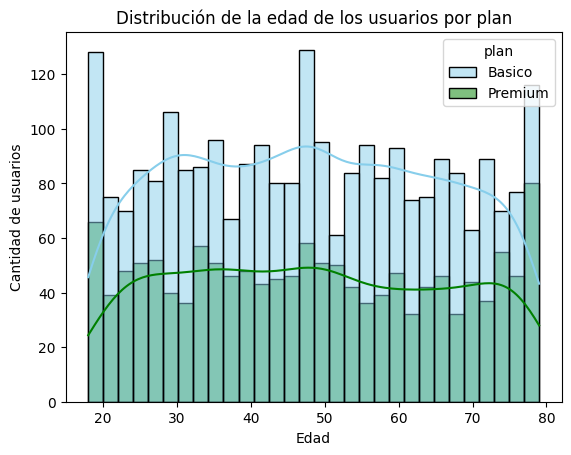

In [35]:

# Histograma para visualizar la edad (age)
sns.histplot(data=users, x='age', hue='plan', palette=['skyblue', 'green'], kde=True, bins=30)
plt.title('Distribución de la edad de los usuarios por plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Histograma completo: <code>hue='plan'</code>, paleta indicada, KDE, título y etiquetas en ambos ejes.
</div>

💡Insights: Los usuarios de ambos planes (Básico y Premium) se encuentran distribuidos de manera bastante homogénea en todas las edades, sin que se aprecie una concentración exclusiva de jóvenes o adultos mayores en un plan en específico.
- Distribución: Es una distribución multimodal / relativamente simétrica a lo largo de los rangos de edad de los usuarios (desde los 20 hasta casi los 80 años).

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Correcta la observación de que ambos planes se distribuyen de forma homogénea en todas las edades.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
La forma se describe mejor como <b>uniforme</b> (barras de altura similar entre 18 y 79 años) que como multimodal.
</div>

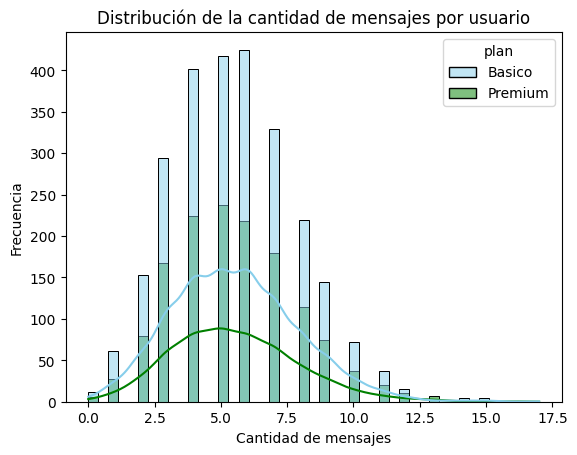

In [38]:

# Histograma para visualizar la cantidad de mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de la cantidad de mensajes por usuario')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: Los usuarios con el plan Básico tienden a enviar menor cantidad de mensajes en comparación con el plan Premium, donde se observa una mayor proporción de clientes que alcanzan volúmenes más altos de mensajes.
- DISTRIBUCION: Sesgada a la derecha (asomando una cola hacia valores más altos).

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Ojo con esta conclusión: en el histograma, las barras de Básico son más altas en todos los valores simplemente porque hay más clientes Básico (65 % vs. 35 %), no porque envíen menos mensajes. Para comparar el <b>comportamiento</b> de cada plan necesitas medidas relativas: compara la media o la mediana por plan con un <code>groupby('plan')</code>, o usa <code>stat='density', common_norm=False</code> en <code>histplot</code>. Verás que ambos planes tienen un consumo prácticamente igual. Este comentario aplica también a llamadas y minutos.
</div>

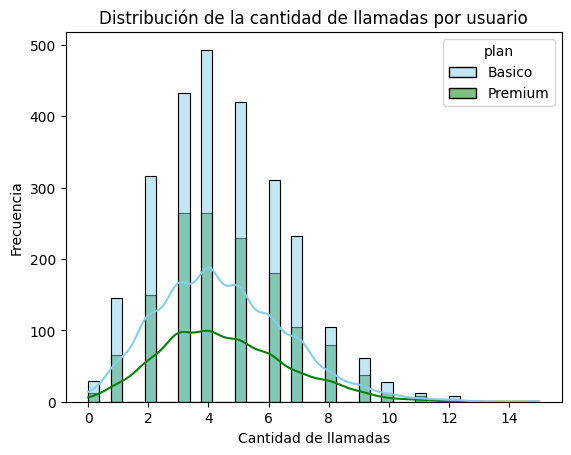

In [39]:

# Histograma para visualizar la cantidad de llamadas (cant_llamadas)
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de la cantidad de llamadas por usuario')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: Los usuarios del plan Premium tienden a realizar una mayor frecuencia de llamadas de forma constante, mientras que los del plan Básico se concentran principalmente en los niveles más bajos de llamadas.
- Distribución: Sesgada a la derecha.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Bien identificado el sesgo a la derecha. La afirmación de que Premium hace más llamadas no está respaldada por los datos (ver comentario anterior); verifícala comparando las medianas por plan.
</div>

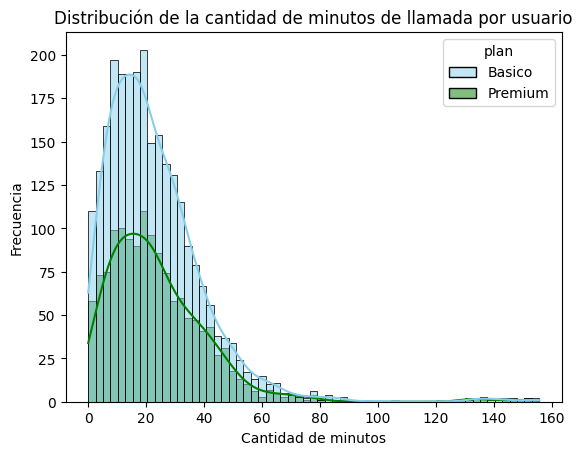

In [40]:

# Histograma para visualizar el total de minutos de llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de la cantidad de minutos de llamada por usuario')
plt.xlabel('Cantidad de minutos')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: Dentro del plan Premium, hay una mayor proporción de usuarios que acumulan una alta cantidad de minutos en llamadas, reflejando el beneficio superior que ofrece su tarifa frente al plan Básico.
- DISTRIBUCION: Sesgada fuertemente hacia la derecha (con una cola larga de usuarios de alto consumo).

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Correcta la forma. Revisa la comparación entre planes con el mismo criterio de antes. Además, <code>cant_minutos_llamada</code> es el <b>total de minutos acumulados por usuario en el año</b>: los valores altos no son necesariamente "llamadas de larga duración", sino usuarios que suman muchos minutos.
</div>

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

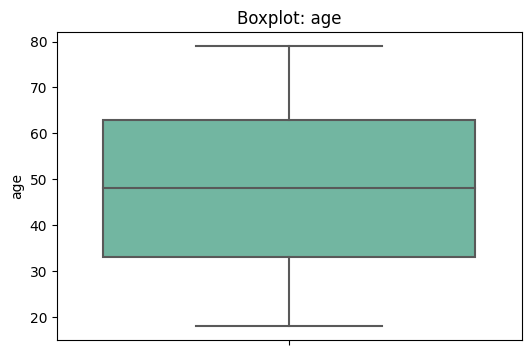

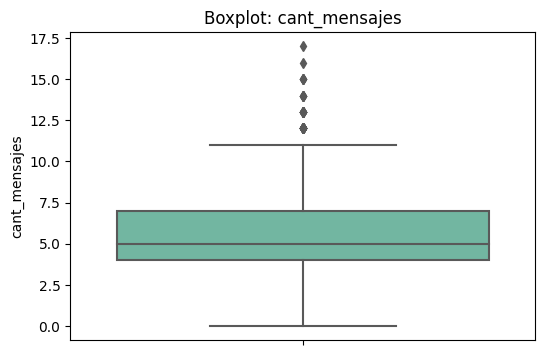

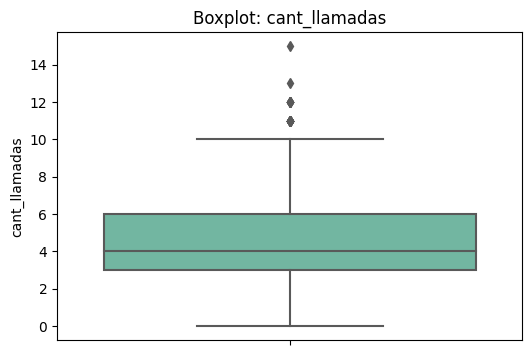

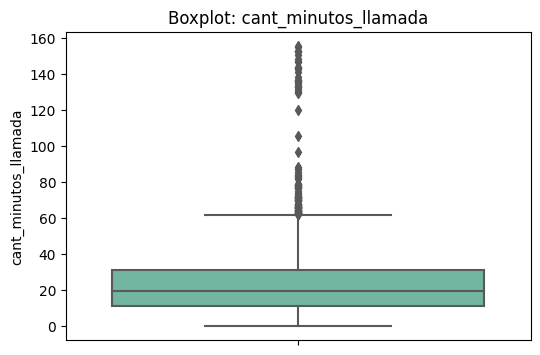

In [42]:

# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=user_profile, y=col, palette='Set2')
    plt.title(f'Boxplot: {col}')
    plt.ylabel(col)
    plt.show()

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Boxplots generados con un ciclo <code>for</code> y título dinámico, tal como se pedía.
</div>


💡Insights: 
- Age: ...(presenta o no outliers). valores anómalos aislados y valores centinelas como el -999 detectados en la limpieza previa, así como edades extremas fuera del rango intercuartílico.
- cant_mensajes: Presenta outliers hacia la derecha; se decide mantenerlos, ya que reflejan un volumen de mensajes legítimo de usuarios muy activos que aprovechan intensamente el servicio de la red.
- cant_llamadas: Presenta valores atípicos superiores; se decide mantenerlos, al representar patrones de uso reales y continuos por parte de los clientes con mayor frecuencia de comunicación.
- cant_minutos_llamada: Presenta una cantidad notable de outliers con una cola larga hacia valores altos; se decide mantenerlos, ya que corresponden a llamadas de larga duración reales (como llamadas de trabajo o familiares extensas) que no deben eliminarse para evitar sesgar el comportamiento de alto consumo.


<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
En <code>age</code>, después de la limpieza ya no queda ningún <code>-999</code> ni outliers: tu propia tabla IQR muestra un límite superior de 108 y un máximo de 79. Corrige este punto y borra el texto de la plantilla. En las otras tres variables, el análisis es correcto.
</div>

In [43]:

# Calcular Límites con el método IQR
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

# Creamos un diccionario vacío para guardar los resultados o revisamos su descripción
# Si la plataforma requiere calcular los límites de forma específica por columna, puedes usar:
Q1 = user_profile[columnas_limites].quantile(0.25)
Q3 = user_profile[columnas_limites].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Mostramos un resumen para comparar el máximo real con el límite superior
limites_df = pd.DataFrame({
    'Min': user_profile[columnas_limites].min(),
    'Q1': Q1,
    'Median': user_profile[columnas_limites].median(),
    'Q3': Q3,
    'Max': user_profile[columnas_limites].max(),
    'Limite_Superior': limite_superior
})

print(limites_df)

                       Min     Q1  Median      Q3     Max  Limite_Superior
age                   18.0  33.00   48.00  63.000   79.00         108.0000
cant_mensajes          0.0   4.00    5.00   7.000   17.00          11.5000
cant_llamadas          0.0   3.00    4.00   6.000   15.00          10.5000
cant_minutos_llamada   0.0  11.12   19.78  31.415  155.69          61.8575


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Excelente! 🌟 Armaste un DataFrame con mínimo, Q1, mediana, Q3, máximo y límite superior para todas las variables a la vez, de forma vectorizada y sin ciclo. Es una forma muy clara y profesional de respaldar la decisión.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Agrega una columna con cuántos usuarios superan el límite para dimensionar los outliers:<br><code>(user_profile[columnas_limites] &gt; limite_superior).sum()</code>
</div>

In [44]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Mantener. representan usuarios altamente activos que aprovechan con mayor intensidad los servicios de mensajería del plan, por lo que eliminarlos sesgaría el comportamiento real de consumo de la comunidad.
- cant_llamadas: mantener o no outliers, porqué? Mantener. Reflejan patrones legítimos de frecuencia de comunicación continua por parte de un segmento de clientes más comunicativo, sin constituir errores técnicos o anomalías de sistema.
- cant_minutos_llamada: mantener o no outliers, porqué? Mantener. A pesar de la cola larga de valores altos hacia la derecha, corresponden a llamadas de larga duración reales (como llamadas de trabajo o de larga distancia), las cuales son fundamentales para entender el uso intensivo de la red y no deben descartarse.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Decisión correcta y bien argumentada: conservar los outliers porque representan clientes muy activos y no errores.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Borra las preguntas de la plantilla ("mantener o no outliers, porqué?") y apóyate en los números de tu tabla (límite vs. máximo). En minutos, recuerda que son totales anuales por usuario, no llamadas individuales.
</div>

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [46]:

# Crear columna grupo_uso basada en condiciones de llamadas y mensajes
def clasificar_uso(row):
    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
La función de segmentación es clara y respeta el orden de las condiciones.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<code>apply(axis=1)</code> recorre las filas una por una y es lento con datasets grandes. La rúbrica sugiere <code>np.where</code> anidados, que son vectorizados y mucho más rápidos:<br><code>np.where(cond_bajo, 'Bajo uso', np.where(cond_medio, 'Uso medio', 'Alto uso'))</code>
</div>

In [47]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Ojo con los nulos: una comparación con <code>NaN</code> siempre da <code>False</code>. El usuario sin actividad no cumple ninguna condición y la función lo manda al <code>else</code>: <b>"Alto uso"</b>, cuando en realidad no usó el servicio. Si rellenas con 0 después del merge, quedará correctamente en "Bajo uso".
</div>

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [49]:

# Crear columna grupo_edad basada en las condiciones solicitadas
def clasificar_edad(age):
    if age < 30:
        return 'Joven'
    elif age < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile['age'].apply(clasificar_edad)

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy bien aplicar la función directamente sobre la columna con <code>user_profile['age'].apply(...)</code>: es más eficiente que recorrer filas completas.
</div>

In [50]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

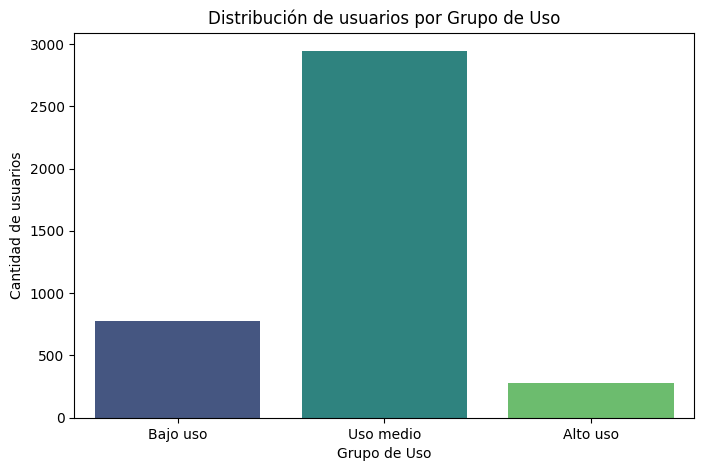

In [51]:

# Visualización de los segmentos por uso
plt.figure(figsize=(8, 5))
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], palette='viridis')
plt.title('Distribución de usuarios por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Countplot con título, etiquetas en ambos ejes y categorías en orden lógico.
</div>

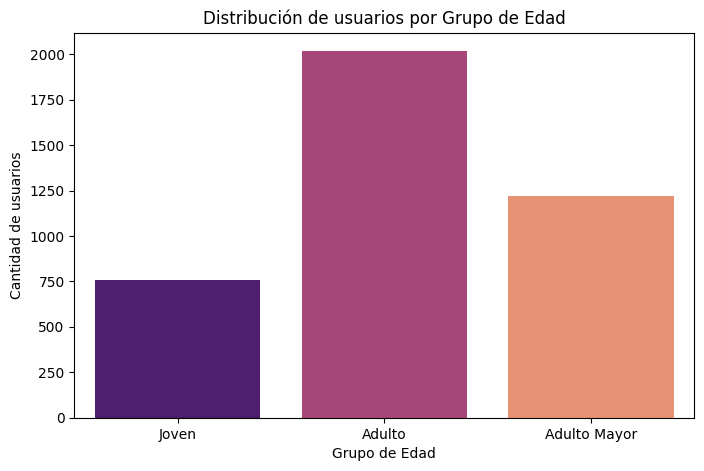

In [52]:

# Visualización de los segmentos por edad
plt.figure(figsize=(8, 5))
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], palette='magma')
plt.title('Distribución de usuarios por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Gráfico de edad también ordenado y bien rotulado. Ambos countplots cumplen lo pedido.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Agrega debajo de los gráficos el tamaño de cada segmento con <code>value_counts(normalize=True)</code>; te servirá directamente para el resumen ejecutivo.
</div>


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
-city (en users): Presentaba un 11.72% de valores faltantes (469 registros), además de valores inválidos representados con signos de interrogación (?), los cuales fueron tratados para evitar sesgos geográficos.

-churn_date (en users): Presentaba un 88.35% de valores faltantes (3,534 registros), lo cual no representaba un error de calidad, sino que indicaba de manera natural que la gran mayoría de los clientes se mantienen activos.

-date (en usage): Presentaba un porcentaje mínimo del 0.12% de nulos (50 registros), siendo un caso menor que no afecta el análisis global.

-duration y length (en usage): Tenían una alta proporción de nulos (55.19% y 44.74%, respectivamente) debido a la estructura mixta de la tabla (filas alternadas entre llamadas y mensajes), por lo que debieron procesarse por separado según el tipo de evento.

-age (en users): Presentaba un valor centinela anómalo extremo de -999 en el mínimo, el cual fue depurado para corregir las métricas estadísticas.


🔍 **Segmentos por Edad**
- Por Grupo de Edad: Se segmentó a los usuarios en Jóvenes (menores de 30 años), Adultos (entre 30 y 59 años) y Adultos Mayores (60 años en adelante), mostrando una distribución amplia en la base de clientes.

-Por Nivel de Uso: Se clasificaron en Bajo uso, Uso medio y Alto uso basándose en la frecuencia de llamadas y mensajes. Los usuarios del plan Premium tienden a concentrarse de manera consistente en los segmentos de mayor consumo, mientras que el plan Básico agrupa principalmente a los usuarios de menor volumen.


📊 **Segmentos por Nivel de Uso**
-El segmento de Alto Uso bajo el plan Premium es el más valioso para la compañía. Estos clientes generan flujos de ingresos más constantes y estables, y aprovechan de forma intensa los servicios de minutos y mensajes, representando el núcleo de rentabilidad y compromiso con la marca.

➡️ Esto sugiere que ... Se decidió mantenerlos ya que no corresponden a fraudes ni errores técnicos, sino a patrones de consumo legítimos de clientes hiperactivos o con necesidades de comunicación extensas (como llamadas laborales o familiares largas). Ignorarlos habría subestimado la capacidad de carga real requerida en la red.


💡 **Recomendaciones**
- Diseñar un plan intermedio o flexible: Crear un nivel tarifario intermedio que capture a los usuarios de "Uso medio" que actualmente se encuentran en el plan Básico pero se acercan al límite.

-Paquetes de minutos adicionales (Add-ons): Ofrecer complementos de minutos y mensajes personalizables orientados a retener a los usuarios identificados como outliers de alto consumo, evitando que incurran en cobros excesivos por excedentes y mejorando su satisfacción.

-Campañas de retención por edad: Enfocar estrategias de fidelización diferenciadas, adaptando la comunicación comercial a las preferencias de los segmentos jóvenes frente a los adultos mayores.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Buen trabajo en la sección de problemas: cuantificas cada columna con porcentaje y cantidad de registros, y explicas por qué los nulos de <code>churn_date</code>, <code>duration</code> y <code>length</code> no son errores.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Para completarlo:
<ul>
<li><b>Problemas:</b> agrega las cantidades de <code>-999</code> (55) y <code>"?"</code> (96), y las 40 fechas de 2026, que no aparecen.</li>
<li><b>Segmentos:</b> indica el tamaño de cada uno (Adulto ~50 %, Adulto Mayor ~31 %, Joven ~19 %; Uso medio ~74 %, Bajo ~19 %, Alto ~7 %).</li>
<li><b>Segmento más valioso:</b> la idea de que Premium se concentra en el alto uso viene de la lectura de los histogramas. Si la verificas con <code>pd.crosstab(user_profile['grupo_uso'], user_profile['plan'], normalize='index')</code>, verás que la proporción de planes es muy similar en los tres grupos. Ajusta la conclusión según lo que encuentres.</li>
<li>El párrafo "Esto sugiere que..." habla de los outliers; conviene que resuma la implicación principal del análisis. Borra los <code>...</code> de la plantilla.</li>
</ul>
</div>

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

<div class="alert alert-block alert-danger">
<b>❌ Comentario del revisor. (Iteración 1) — Necesita arreglos</b> <a class="tocSkip"></a><br>
Falta el <b>link al repositorio de GitHub</b>: la celda conserva el texto de la plantilla. Este paso es parte de la entrega, porque permite revisar que el proyecto esté publicado y sea reproducible.<br><br>
Para la próxima iteración:
<ol><li>Crea un repositorio público y sube el notebook.</li>
<li>Agrega un <code>README.md</code> con el objetivo del proyecto, los datasets usados, las etapas del análisis y cómo ejecutar el notebook.</li>
<li>Pega aquí el link (en esta celda Markdown, sin comillas invertidas, para que se pueda hacer clic).</li></ol>
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<b>📊 Evaluación según la rúbrica DA Sprint 7</b><br><table><tr><th>Parte</th><th>Criterio</th><th>Estado</th></tr><tr><td>1. Carga y exploración</td><td>Librerías, carga, head/info/shape</td><td>✅</td></tr><tr><td>2. Calidad de datos</td><td>Nulos (conteo y proporción)</td><td>✅</td></tr><tr><td></td><td>Sentinels (-999 y "?")</td><td>✅</td></tr><tr><td></td><td>Fechas (errors='coerce', .dt.year)</td><td>✅</td></tr><tr><td></td><td>Diagnóstico escrito</td><td>🟡 celdas de interpretación sin completar</td></tr><tr><td>3. Limpieza</td><td>Mediana en age + validación</td><td>✅</td></tr><tr><td></td><td>"?" → pd.NA</td><td>✅</td></tr><tr><td></td><td>Fechas imposibles → nulo</td><td>✅</td></tr><tr><td></td><td>Evaluación MAR</td><td>🟡 falta verificar length</td></tr><tr><td></td><td>Decisión justificada</td><td>✅</td></tr><tr><td>4. Uso por usuario</td><td>Agrupación, métricas y merge</td><td>✅ (sugerencia: fillna(0))</td></tr><tr><td></td><td>Revisión estadística</td><td>🟡 falta interpretación escrita</td></tr><tr><td>5. Distribuciones y outliers</td><td>Histogramas con hue</td><td>✅</td></tr><tr><td></td><td>Interpretación</td><td>🟡 comparación entre planes sin respaldo</td></tr><tr><td></td><td>Boxplots e IQR</td><td>✅</td></tr><tr><td>6. Segmentación</td><td>grupo_uso / grupo_edad</td><td>✅ (ojo con NaN → Alto uso)</td></tr><tr><td></td><td>Countplots rotulados</td><td>✅</td></tr><tr><td>7. Insight ejecutivo</td><td>Segmentos y comportamiento</td><td>🟡 sin tamaños; conclusión de planes a revisar</td></tr><tr><td></td><td>Recomendaciones</td><td>✅</td></tr><tr><td>8. Publicación</td><td>Link, notebook y README en GitHub</td><td>❌ no se incluyó el link</td></tr></table><br>Un criterio en ❌ → <b>proyecto devuelto para una nueva iteración</b>.
</div>

<div class="alert alert-block alert-info">
<b>Comentario del revisor. (Iteración 1) — Próximos pasos</b> <a class="tocSkip"></a><br><br>
Tu proyecto tiene una base técnica muy sólida y está a un paso de la aprobación. Para la siguiente iteración, el único punto bloqueante ❌ es:
<ol><li><b>Publicar el proyecto en GitHub (paso 8):</b> repositorio público con el notebook y un <code>README.md</code>, y el link en la celda correspondiente.</li></ol>
En la siguiente iteración revisaré únicamente este punto, así que no habrá requisitos nuevos. Las recomendaciones 🟡 son opcionales, aunque te sugiero especialmente completar las celdas de interpretación de los pasos 2.2 y 2.3 y revisar con datos la comparación entre planes antes de llevarla al resumen ejecutivo.<br><br>
¡Ánimo, ya casi está! 💪
</div>